In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import numpy as np
import gsw

from utils import make_map, subplots_structure

import sys
sys.path.insert(0, '/home/danilo/phd/repos/detectionAlgorithm')
# from subintrusion_detection import detection

# Functions

In [2]:
from numpy.lib.function_base import diff
import xarray as xr
import numpy as np
import pandas as pd

from tqdm import trange

def get_dens(ds, zmax):

    x = (ds['dens'].values).flatten()
    y = ds['depth'].values

    idy = np.where(y==zmax)[0].item()
    
    x = x[idy]
    
    if x > 1000:
        x -= 1000
    
    return x
    
####################################################################################################

def get_layer_limit(S, Smax, Smin, factor=0.95):
    """
    This auxiliar function gets a vertical profile of salinity, its maximum and minimum salinities and then
    find the subsurface intrusion limit, based on Lentz (2003):
    
    S_{max} - S(z=z_t) = 0.95 * (S_{max} - S_{min})
    
    Output
    ------
    int  : 
        index of the limit happen.
    """
    # compute the salinity limit
    Slimit = - factor * (Smax - Smin) + Smax
    
    # get the position of this limit
    deltaS = S.flat[np.abs(S - Slimit).argmin()]
    Ilimit = np.argwhere(S == deltaS)
    
    # if Ilimit has more than one match, then return only the last one (probably due to a well mixed region)
    if isinstance(Ilimit, np.ndarray):
        return int(Ilimit[-1])
    else:
        return Ilimit

####################################################################################################

def intrusion_info(profile, factor=0.95, flag_threshold=5, salt_name='salt', temp_name='temp'):
    """ Based on the methods proposed by Lentz (2003), this function compute some features of the intrusion, like thickness, 
    top and bottom depth limits, anomaly, etc.
    
    parameters
    ----------
    profile : xarray.Dataset
        Cast.
    factor : float
        Factor used to find the top and bottom limits of the intrusion.
    flag_threshold : float, int
        Minimum depth to be considered a subsurface intrusion away from the surface. Default is 5 meters.
    
    output
    ------
    intrusion : dict
        Dictionary containing all features of the intrusion.
        
    reference
    ---------
        Lentz, S. (2003). A climatology of salty intrusions over the continental shelf from Georges Bank to Cape Hatteras. 
        Journal of Geophysical Research: Oceans
    """
    # find the maximum salinity of the vertical profile
    Smax,Tmax,Imax = np.nanmax(profile[salt_name]), np.nanmax(profile[temp_name]), np.nanargmax(profile[salt_name])
    
    # Split cast into upper and lower layers, based on the position of maximum salinity
    upper_layer = profile.isel(depth=slice(0, Imax+1))
    lower_layer = profile.isel(depth=slice(Imax, -1))
    
    #########################################################################
    #-- defining the upper layer limits, based on Lentz (2003) definition --#
    #########################################################################
    
    # get the vertical level index referring to the salinity value
    It_limit = get_layer_limit(upper_layer[salt_name].values, 
                               Smax, 
                               upper_layer[salt_name].min().item(), 
                               factor=factor)
    
    # get the salinity of the top limit (St) and its vertical level (Zt)
    St = upper_layer.isel(depth=It_limit)[salt_name].item()
    Tt = upper_layer.isel(depth=It_limit)[temp_name].item()
    Zt = upper_layer.isel(depth=It_limit).depth.item()
    
    #########################################################################
    #-- defining the lower layer limits, based on Lentz (2003) definition --#
    #########################################################################
    
    # get the salinity of the bottom limit (Sb) and its vertical level (Zb)
    # in case the bottom layer has 0 depth information, which means the maximum salinity
    # is very near the bottom, we assume the last valid value of salinity as the bottom limit.
    # Otherwise, we compute the bottom limit using the definition of Lentz (2003)
    if lower_layer.dims['depth'] == 0:
        hack_values = profile.isel(depth=Imax)
        Sb, Tb, Zb = hack_values[salt_name].item(), hack_values[temp_name].item(), hack_values.depth.item()
    else:
        Ib_limit = get_layer_limit(lower_layer[salt_name].values, 
                                   Smax, 
                                   upper_layer[salt_name].min().item(), 
                                   factor=factor)
        
        Sb = lower_layer.isel(depth=Ib_limit)[salt_name].item()
        Tb = lower_layer.isel(depth=Ib_limit)[temp_name].item()
        Zb = lower_layer.isel(depth=Ib_limit).depth.item()
    
    # FIXME: Resolver problema atual em caso da camada inferior seja nula. Estou atribuindo o mesmo valor que Smax e isso gera erro na hora de computar a anomalia de salinidade (= 0)
    # if the lower layer has zero values (which means the maximum salinity occurs near the bottom), we 
    # use the upper layer minimum salinity to compute the anomaly. Otherwise, apply the anomaly definition
    # of Lentz (2003), using the lower layer minimum salinity
    anomaly = Smax - Sb # hack: considering the S_bottom == Smax for now. It will generate a null anomaly. I still have to think how to solve

    if Zt <= flag_threshold:
        flag = 0 # near-surface
    elif lower_layer.dims['depth'] == 0:
        flag = 2 # near-bottom
    else:
        flag = 1 # subsurface
    
    # put all information possible into a dictionary and return it
    intrusion = {
        'proj': profile.project.values.item(), #.lower(),
        'cast': profile.cast.values.item(), #.lower(),
        'top_salt': St,
        'top_temp': Tt,
        'top_dep': Zt,
        'bottom_salt': Sb,
        'bottom_temp': Tb,
        'bottom_dep': Zb,
        'max_salt': Smax,
        'max_temp': Tmax,
        'max_dep': profile.isel(depth=Imax).depth.values.item(),
        'thickness': Zb - Zt,
        'salt_anomaly': anomaly,
        'flag': flag # 0 -> Near-surface, 1 -> Subsurface, 2 -> Near-bottom
    }
    
    return intrusion

####################################################################################################

def drop_nans(ds, var, dim='depth'):
    """reconstruct a new xarray.Dataset removing values where `var` is nan

    This functions removes values where depth is nan. It must be made because the indexing of several projects generates a problem with 
    depth, where profiles without a specific depth will vane a nan value.

    Parameters
    ----------
    ds : xarray.Dataset
        Dataset with profile indexed by depth, containing at least salinity.
    var : str
        Which variable must be used to clean out nan values
    dim : str, optional
        Which dimension must be used to remove nan values, by default 'depth'

    Returns
    -------
    xarray.Dataset
        Dataset with clean profile.
    """
    
    # for a given variable, drop nan values from it
    new_var = ds[var].dropna(dim=dim)
    
    # create a dictionary to use in .sel()
    selection = {dim: new_var.depth.values}

    # create a new dataset only with the valid values based on the variable given
    ds_new = ds.sel(**selection)
    
    ds_new[var] = new_var
    
    return ds_new

####################################################################################################

def detection(ds, depth_limit=110,
                  salt_name='salt',
                  temp_name='temp',
                  var='dSdz', 
                  threshold=0.1, 
                  verbose=False, 
                  factor=0.95,
                  watermass_threshold=35.8,
                  method='old'):
    """Perform subsurface intrusion detection, based on Lentz (2003) methodology.

    Main function of this package, that controls the pipeline of functions to identify subsurface intrusions. A big 
    xarray.Dataset (ds) must be pass as main argument, containing all vertical profiles indexed by depth and cast and 
    containing at least the salinity variable.
    
    The methodology to identify the intrusions is based on the work of Lentz (2003) with minor adaptations. In this routine,
    we add a third condition to be considered a salty intrusion, that is controlled by the watermass_threshold argument. This
    was done to only account salty subsurface, otherwise every big variation of salinity would become a subsurface salty intrusion.

    The intrusion is considered when:
        1. dSdz > threshold (0.1 by default)
        2. maximum salinity is higher than watermass_threshold (35.8 by default)
        3. if the maximums salinity is away the surface (Zmax <= 1m)
        
    The method of Lentz (2003) described that an intrusion will occur when the vertical salinity gradient is higher, in at least one
    vertical position, than a threshold. The features (like thickness, salt anomaly, etc) related to this intrusion can be found using
    derivative informations from the vertical profile.
    
    Top and Bottom intrusion limits
        The vertical positions that limits the intrusion are found using the following equation:
        
        S_{max} - S(z=z_t) = 0.95 * (S_{max} - S_{min}),
        
        where Smin is related to each layer (upper: above the Zmax, lower: below the Zmax) and Smax is the maximum salinity in the profile.
        
    Thickness
        Knowing the limits of the intrusino, its thickness is found with by subtracting both limits.
        
    Salinity anomaly
        By definition, the salinity anomaly is found by subtracting the maximum salinity and the minimum salinity in the lower layer.    

    Parameters
    ----------
    ds : xarray.Dataset
        Dataset containing all vertical profiles, classified by proj and cast
    depth_limit : int, optional
        Argument to filter profiles with localdepth < depth_limit, by default 110 [m]
    salt_name : str
        Name of the variable correspondent to the salinity on the dataset, by default is 'salt'.
    var : str, optional
        Variable to be used as threshold to identify an intrusion, by default 'dSdz', which means the vertical salinity gradient.
    threshold : float, optional
        Threshold of vertical salinity gradient to be considered an intrusion, by default 0.1.
    verbose : bool, optional
        Boolean controller for debug purposes, by default False
    factor : float, optional
        Factor used to find the top/bottom intrusion limit. This is used to find the vertical layer where the salinity represents 
        factor*DeltaS (between minimum and maximum salinity), by default 0.95.
    watermass_threshold : float, optional
        Water mass salinity used to consider whether is a salty intrusion or not, by default 35.8 [psu]

    Output
    ------
    xarray.Dataset  :
        Profiles with intrusion identified.
    pandas.DataFrame  :
        Features related to each intrusion.
    
    Usage
    -----
        >>> 
        >>>
        >>>
        
    References
    ----------
        Lentz, S. (2003). A climatology of salty intrusions over the continental shelf from Georges Bank to Cape Hatteras. 
        Journal of Geophysical Research: Oceans
    """
    
    # filtering casts by depth_limit. Useful when working with a specific region, e.g. inner shelf
    subset = ds.where(ds['localdepth'] <= depth_limit, drop=True)
    
    # create empty data structures to insert profiles with intrusion detected
    profiles = []
    
    columns = ['proj', 'cast', 'top_salt', 'top_dep', 'bottom_salt', 'bottom_dep', 'max_salt', 'max_dep', 'thickness', 'salt_anomaly', 'flag']
    df_intrusions = pd.DataFrame(columns=columns)
    
    # number of vertical profiles available
    N = subset.dims['cast']
    
    for ncast in trange(N, desc='Detecting intrusions'):
        if verbose:
            print(ncast)
        
        # extract single profile
        profile = subset.isel(cast=ncast)
        
        # first treatment: removing depth with nan values
        profile = drop_nans(profile, var=salt_name, dim='depth')
        
        # if we have a valid profile (more than 5 observations and 
        # the distance between adjacent observations is lower than 30)
        if (profile.dims['depth'] >= 5) and (profile['depth'].where(profile['depth'].diff(dim='depth') > 30).count().values == 0):
            # TODO: first round of check: distobs

            # get the vertical salinity gradient, used to find the intrusion
            profile['dSdz'] = profile[salt_name].differentiate('depth')
            # get only the discrete difference along the vertical axis
            profile['dS'] = profile[salt_name].diff(dim='depth')
            
            #----! begin of conditions for an intrusion !----#
            
            # get the maximum salinity and its index
            Smax,Imax = np.nanmax(profile[salt_name]), np.nanargmax(profile[salt_name])
                       
            # 1st condition: at least one occurrence of dSdz > threshold?
            if method == 'old':
                threshold_condition = True if profile[var].where(profile[var] >= threshold).count().values != 0 else False
            elif method == 'new':
                threshold_condition = True if profile[var].where((profile[salt_name][Imax:] - Smax) <= -0.1).count().values != 0 else False
            elif method == 'double':
                query1 = True if profile[var].where(profile[var] >= threshold).count().values != 0 else False
                query2 = True if profile[var].where((profile[salt_name][Imax:] - Smax) <= -(threshold/2)).count().values != 0 else False
                if query1 and query2:
                    threshold_condition = True
                else:
                    threshold_condition = False
            else:
                raise ValueError('method unvailable: select between old, new or double')
            
            # 2nd condition: the maximum salinity is higher than the watermass threshold used as proxy?
            watermass_condition = Smax >= watermass_threshold
            
            # 3rd condition: is a subsurface intrusion?
            # if the maximum salinity happen at the surface (Zmax <= 1m), it is not subsurface
            if profile.isel(depth=Imax).depth.item() <= 1:
                subsurface_condition = False
            else:
                subsurface_condition = True
            
            # alternative subsurface condition
            # upper_layer = profile.isel(depth=slice(0, Imax+1))
            
            # if upper_layer.dims['depth'] == 0:
            #     subsurface_condition = False
            # else:
            #     subsurface_condition = True
            
            # if all conditions are True, then we have an subsurface intrusion
            if threshold_condition & watermass_condition & subsurface_condition:
                
                # save the profile
                profiles.append(profile)
                
                # compute intrusion features, like,thickness, salt anomaly, etc
                intrusion_features = intrusion_info(profile, factor=factor, salt_name=salt_name, temp_name=temp_name)
                key = f"{intrusion_features['proj']}/{intrusion_features['cast']}"
                df_ = pd.DataFrame(intrusion_features, index=[key])
                # save feature into a pandas.DataFrame
                df_intrusions = df_intrusions.append(pd.DataFrame(df_))
   
                
    if len(profiles) > 0:
        ds_profiles = xr.concat(profiles, dim='cast')
        ds_profiles['project'] = ds_profiles['project'].str.lower()
        ds_profiles['cast'] = ds_profiles['cast'].str.lower()
    else:
        ds_profiles = xr.Dataset()
        
    return ds_profiles, df_intrusions

####################################################################################################

def test():
    """Test function.

    Returns
    -------
    xarray.Dataset
        .
    pandas.Dataframe
        .
    """
    # set paths
    datadir = '/media/Danilo/Research/PhD/thesis/subsurfaceIntrusion/data/observational'
    projects = ['deproas', 'piof', 'coroas', 'ecosan', 'bndo', 'baciasantos', 'ocse']

    # create list with full path for each project's files
    nfiles = [f"{datadir}/{fname}_tratado.nc" for fname in projects]

    ds_list = []
    for fname in nfiles:
        ds = xr.open_dataset(fname)
        # if density exist, drop out
        if 'dens' in list(ds.keys()):
            ds = ds.drop_vars('dens')
            
        ds_list.append(ds)

    ds = xr.concat(ds_list, dim='cast')

    # run algorithm
    ds_intrusions,df_intrusions = detection(ds)
    
    return ds_intrusions,df_intrusions

def fake_processing(fname, project='SANAGU'):
    profile = xr.open_dataset(fname)
    cast = profile.to_dataframe()

    # removing useless columns
    cols = ["sa", "ct", "rho", "depSM"]
    cast.reset_index(inplace=True)
    cast = cast[cols]
    
    cast = cast.rename(columns={'depSM': 'depth', 'sa': 'salt', 'ct': 'temp', 'rho': 'dens'})

    cast['cast'] = fname.split('/')[-1].split('.nc')[0]
    
    ds = cast.dropna(axis=0, how='any').set_index(['cast', 'depth']).to_xarray()

    ds['project'] = (('cast'), ds.cast.shape[0] * [project])
    ds['datetime'] = profile.attrs['time']
    return ds


# Application

In [3]:
from glob import glob
varb = 'sa'

fnames = ['/home/danilo/phd/thesis/chapter_colab/scripts/section-ctd_dalton/data/umassd2/treated/SANAGU15_H2_CTD_2_OT.nc',
          '/home/danilo/phd/thesis/chapter_colab/scripts/section-ctd_dalton/data/umassd2/treated/SANAGU14_G4_CTD_1_OT.nc']

ds_list = []
for fname in fnames:   
    cast = fake_processing(fname, project='SANAGU')
    dtime = cast['datetime'].values
    
    cast['localdepth'] = 4000

    ds, df = detection(cast, 
                       depth_limit=5000, 
                       salt_name='salt', 
                       temp_name='temp', 
                       threshold=0.1,
                       var='dS',
                       method='old',
                       factor=0.75,
                       watermass_threshold=35)
    if not df.empty:
        df['max_dens'] = get_dens(ds,df['max_dep'].item())
        # converting intrusive features from dataframe to dataset
        ds_features = df.reset_index(drop=True).rename(columns={'proj': 'project'}).set_index(['cast']).to_xarray()

        for varb in ds_features.data_vars:
            ds[varb] = (('cast'), ds_features[varb].values)
        ds['datetime'] = dtime

        ds_list.append(ds)
        
ds = xr.concat(ds_list, dim='cast')
ds_ctd = ds.copy(deep=True)

Detecting intrusions: 100%|██████████| 1/1 [00:00<00:00, 176.94it/s]


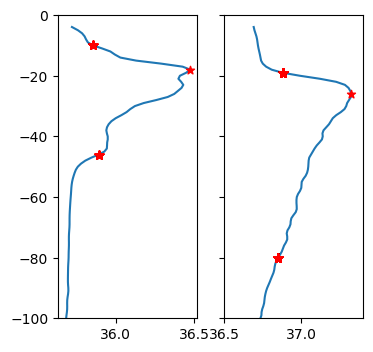

In [84]:
fig,axes = plt.subplots(ncols=2, figsize=(10/2.54,10/2.54), sharey=True)

for i,ax in enumerate(axes.ravel()):
    profile = ds.isel(cast=i)
    dtime = pd.to_datetime(profile.datetime.values).strftime('%Y-%m-%d')
    profile = profile.to_dataframe().dropna(axis=0, how='any')
    
    x = profile.salt.values
    y = profile.index.values

    ax.plot(x, -y)
    
    ax.scatter(profile['max_salt'].values[0], 
               profile['max_dep'].values[0]*(-1), marker='*', color='r', zorder=5)
    
    ax.scatter(profile['top_salt'].values,
               profile['top_dep'].values*(-1), marker='*', color='r', zorder=5)
    
    ax.scatter(profile['bottom_salt'].values,
               profile['bottom_dep'].values*(-1), marker='*', color='r', zorder=5)
        
    ax.set_ylim([-100,0])
    if i == 1:
        ax.set_xlim([36.5,37.4])

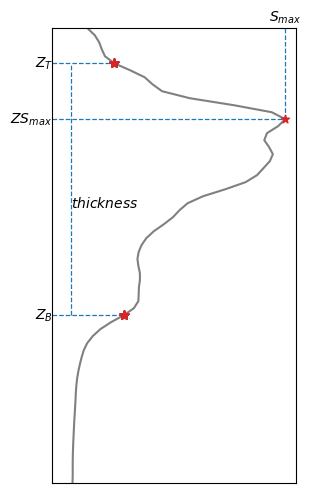

In [139]:
fig,ax = plt.subplots(figsize=(8/2.54, 15/2.54))
i = 0
profile = ds.isel(cast=i)
dtime = pd.to_datetime(profile.datetime.values).strftime('%Y-%m-%d')
profile = profile.to_dataframe().dropna(axis=0, how='any')

x = profile.salt.values
y = profile.index.values

ax.plot(x, -y, c='gray')

ax.scatter(profile['max_salt'].values[0], 
           profile['max_dep'].values[0]*(-1), marker='*', color='tab:red', zorder=5)

ax.scatter(profile['top_salt'].values,
           profile['top_dep'].values*(-1), marker='*', color='tab:red', zorder=5)

ax.scatter(profile['bottom_salt'].values,
           profile['bottom_dep'].values*(-1), marker='*', color='tab:red', zorder=5)

# horizontal lines
ax.axhline(y=profile['max_dep'].values[0]*(-1),
          xmin=0,
          xmax=0.95, c='tab:blue', ls='--', lw=0.9)

ax.axhline(y=profile['top_dep'].values[0]*(-1),
          xmin=0,
          xmax=0.25, c='tab:blue', ls='--', lw=0.9)

ax.axhline(y=profile['bottom_dep'].values[0]*(-1),
          xmin=0,
          xmax=0.3, c='tab:blue', ls='--', lw=0.9)

# vertical lines
ax.axvline(x=profile['max_salt'].values[0],
          ymin=0.8,
          ymax=1, c='tab:blue', ls='--', lw=0.9)

ax.axvline(x=35.7,
          ymin=0.37,
          ymax=0.92, c='tab:blue', ls='--', lw=0.9)

# textual elements
_ = ax.text(35.48, profile['max_dep'].values[0]*(-1), r'$ZS_{max}$', va='center')
_ = ax.text(35.57, profile['top_dep'].values[0]*(-1), r'$Z_{T}$', va='center')
_ = ax.text(35.57, profile['bottom_dep'].values[0]*(-1), r'$Z_{B}$', va='center')
_ = ax.text(35.7, -30, r'$thickness$', va='center')
_ = ax.text(profile['max_salt'].values[0], -4, r'$S_{max}$', ha='center')

_ = ax.tick_params(top=False, labeltop=False, bottom=True, labelbottom=True)
_ = ax.set_yticks([])
_ = ax.set_xticks([])

ax.set_ylim([-70,-5])

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_smax_schematic.png', bbox_inches="tight", dpi=300)

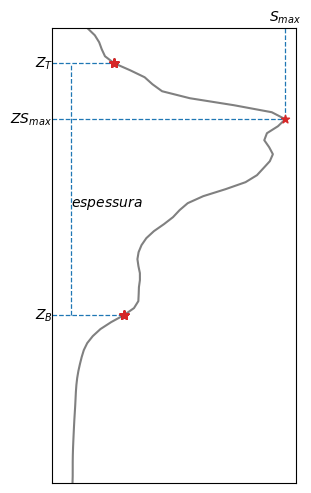

In [5]:
fig,ax = plt.subplots(figsize=(8/2.54, 15/2.54))
i = 0
profile = ds.isel(cast=i)
dtime = pd.to_datetime(profile.datetime.values).strftime('%Y-%m-%d')
profile = profile.to_dataframe().dropna(axis=0, how='any')

x = profile.salt.values
y = profile.index.values

ax.plot(x, -y, c='gray')

ax.scatter(profile['max_salt'].values[0], 
           profile['max_dep'].values[0]*(-1), marker='*', color='tab:red', zorder=5)

ax.scatter(profile['top_salt'].values,
           profile['top_dep'].values*(-1), marker='*', color='tab:red', zorder=5)

ax.scatter(profile['bottom_salt'].values,
           profile['bottom_dep'].values*(-1), marker='*', color='tab:red', zorder=5)

# horizontal lines
ax.axhline(y=profile['max_dep'].values[0]*(-1),
          xmin=0,
          xmax=0.95, c='tab:blue', ls='--', lw=0.9)

ax.axhline(y=profile['top_dep'].values[0]*(-1),
          xmin=0,
          xmax=0.25, c='tab:blue', ls='--', lw=0.9)

ax.axhline(y=profile['bottom_dep'].values[0]*(-1),
          xmin=0,
          xmax=0.3, c='tab:blue', ls='--', lw=0.9)

# vertical lines
ax.axvline(x=profile['max_salt'].values[0],
          ymin=0.8,
          ymax=1, c='tab:blue', ls='--', lw=0.9)

ax.axvline(x=35.7,
          ymin=0.37,
          ymax=0.92, c='tab:blue', ls='--', lw=0.9)

# textual elements
_ = ax.text(35.48, profile['max_dep'].values[0]*(-1), r'$ZS_{max}$', va='center')
_ = ax.text(35.57, profile['top_dep'].values[0]*(-1), r'$Z_{T}$', va='center')
_ = ax.text(35.57, profile['bottom_dep'].values[0]*(-1), r'$Z_{B}$', va='center')
_ = ax.text(35.7, -30, r'$espessura$', va='center')
_ = ax.text(profile['max_salt'].values[0], -4, r'$S_{max}$', ha='center')

_ = ax.tick_params(top=False, labeltop=False, bottom=True, labelbottom=True)
_ = ax.set_yticks([])
_ = ax.set_xticks([])

ax.set_ylim([-70,-5])

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_smax_schematic_ptbr.png', bbox_inches="tight", dpi=300)